Training: 20,000 updates; checkpoints: [5000, 10000, 20000]
Integrator comparison: 100 test drums, K=32; NFE = network evaluations per draw.


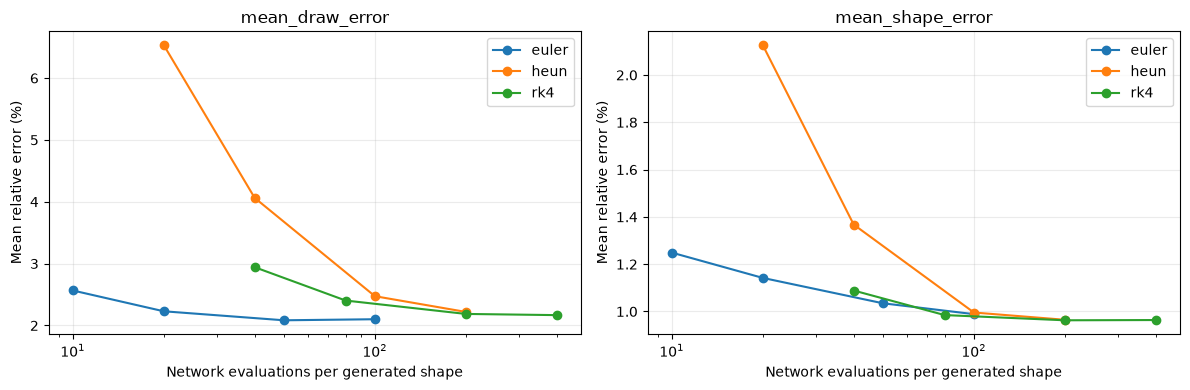

In [1]:
# Aligned model: 20,000 updates, checkpoints at 5,000 / 10,000 / 20,000.
# Integrator comparison: the final model, 100 test drums, 32 draws per drum.
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
get_ipython().run_line_magic("matplotlib", "inline")

root = Path.cwd()
if not (root / "triangle_drums.npz").exists():
    root = root.parent
results = root / "results/aligned_flow_long_20261027"
metadata = json.loads((results / "metadata.json").read_text())
integrators = pd.read_csv(results / "integrators.csv")
print(f"Training: {metadata['updates']:,} updates; checkpoints: {metadata['checkpoints']}")
print("Integrator comparison: 100 test drums, K=32; NFE = network evaluations per draw.")

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, metric in zip(axes, ("mean_draw_error", "mean_shape_error")):
    for method, group in integrators[integrators["metric"] == metric].groupby("integrator"):
        group = group.sort_values("nfe")
        ax.plot(group["nfe"], 100 * group["mean"], "o-", label=method)
    ax.set(xscale="log", xlabel="Network evaluations per generated shape",
           ylabel="Mean relative error (%)", title=metric)
    ax.grid(alpha=.25)
    ax.legend()
fig.tight_layout()
plt.show()

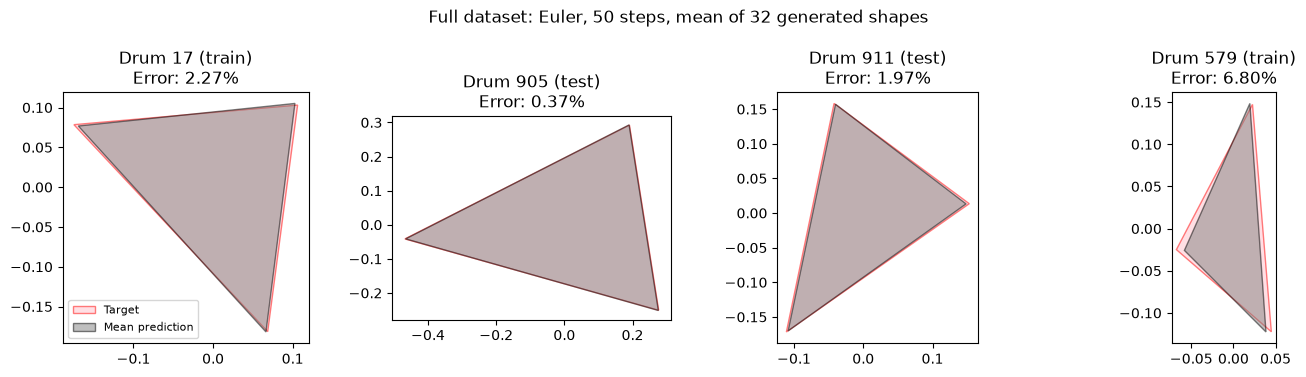

In [2]:
# Full-dataset inference: Euler, 50 steps, mean of 32 aligned generated triangles.
# The target is used only for scoring and display alignment.
from itertools import permutations

inference = np.load(results / "full_dataset.npz")
preprocessing = np.load(results / "preprocessing.npz")
orderings = np.array(list(permutations(range(3))))

def align_for_display(target, prediction):
    target = target - target.mean(axis=0, keepdims=True)
    prediction = prediction - prediction.mean(axis=0, keepdims=True)
    candidates = prediction[orderings]
    u, _, vt = np.linalg.svd(candidates.transpose(0, 2, 1) @ target, full_matrices=False)
    candidates = candidates @ (u @ vt)
    best = np.argmin(np.sum((candidates - target) ** 2, axis=(1, 2)))
    return target, candidates[best]

worst_id = int(inference["dataset_ids"][np.argmax(inference["mean_shape_error"])])
example_ids = [17, 905, 911, worst_id]  # Edit IDs to inspect other drums; last is the worst mean shape.
fig, axes = plt.subplots(1, len(example_ids), figsize=(14, 3.8))
for ax, drum_id in zip(axes, example_ids):
    i = int(np.flatnonzero(inference["dataset_ids"] == drum_id)[0])
    target, prediction = align_for_display(
        preprocessing["vertices"][drum_id], inference["mean_shapes"][i]
    )
    ax.fill(target[:, 0], target[:, 1], facecolor="pink", edgecolor="red", alpha=.5, label="Target")
    ax.fill(prediction[:, 0], prediction[:, 1], facecolor="grey", edgecolor="black", alpha=.5, label="Mean prediction")
    split = "train" if drum_id < metadata["n_train"] else "test"
    ax.set(title=f"Drum {drum_id} ({split})\nError: {inference['mean_shape_error'][i]:.2%}", aspect="equal")
axes[0].legend(fontsize=8)
fig.suptitle("Full dataset: Euler, 50 steps, mean of 32 generated shapes")
fig.tight_layout()
plt.show()

In [3]:
# Full-dataset statistics: errors are displayed in percent.
# mean_draw_error = mean of 32 individual errors for each drum.
# mean_shape_error = error of the mean of 32 generated, mutually aligned shapes.
statistics = pd.read_csv(results / "full_dataset_stats.csv")
percent_columns = ["mean", "median", "min", "max", "p5", "p95", "std"]
statistics[percent_columns] *= 100
columns = ["split", "metric", "count", *percent_columns]
print("Final checkpoint: 20,000 updates; Euler: 50 steps; K=32. All = 1,000 drums.")
display(statistics[columns].rename(columns={c: f"{c}, %" for c in percent_columns}).round(3))

Final checkpoint: 20,000 updates; Euler: 50 steps; K=32. All = 1,000 drums.


,split,metric,count,"mean, %","median, %","min, %","max, %","p5, %","p95, %","std, %"
0,all,mean_draw_error,1000,2.039,1.456,0.250,12.553,0.447,5.529,1.771
1,all,mean_shape_error,1000,1.045,0.763,0.018,6.796,0.187,3.086,0.926
2,train,mean_draw_error,900,2.034,1.458,0.250,12.553,0.440,5.621,1.765
3,train,mean_shape_error,900,1.046,0.763,0.018,6.796,0.185,3.075,0.928
4,test,mean_draw_error,100,2.084,1.370,0.388,9.458,0.542,5.108,1.819
5,test,mean_shape_error,100,1.035,0.756,0.077,5.303,0.207,3.093,0.905


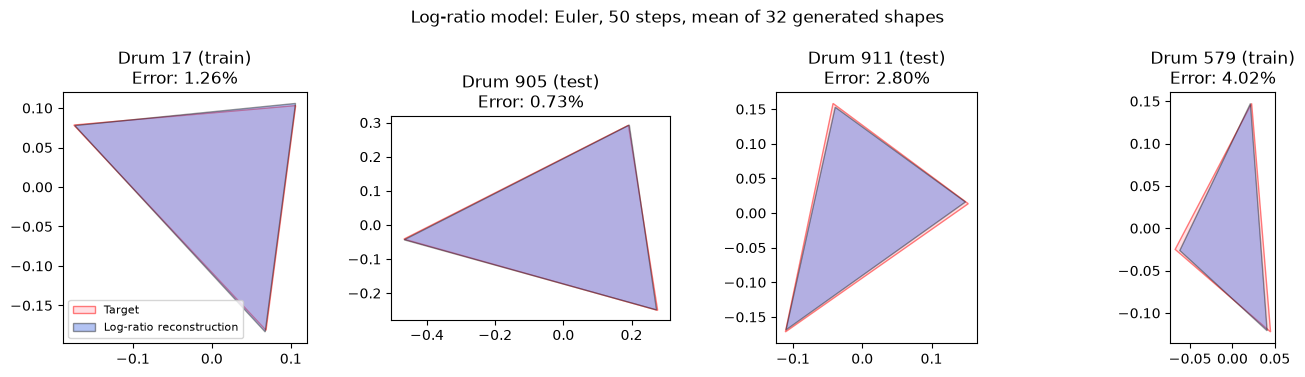

In [4]:
# Log-ratio features: original triangles versus reconstructions of the new model only.
# Euler, 50 steps, mean of 32 generated shapes; target alignment is for display.
ratio_results = root / "results/aligned_flow_log_ratios_20261027"
ratio_inference = np.load(ratio_results / "full_dataset.npz")
ratio_preprocessing = np.load(ratio_results / "preprocessing.npz")
ratio_metadata = json.loads((ratio_results / "metadata.json").read_text())
ratio_example_ids = [17, 905, 911, 579]  # Edit to inspect other dataset IDs.

fig, axes = plt.subplots(1, len(ratio_example_ids), figsize=(14, 3.8))
for ax, drum_id in zip(axes, ratio_example_ids):
    i = int(np.flatnonzero(ratio_inference["dataset_ids"] == drum_id)[0])
    target, prediction = align_for_display(
        ratio_preprocessing["vertices"][drum_id], ratio_inference["mean_shapes"][i]
    )
    ax.fill(target[:, 0], target[:, 1], facecolor="pink", edgecolor="red", alpha=.5, label="Target")
    ax.fill(prediction[:, 0], prediction[:, 1], facecolor="royalblue", edgecolor="black", alpha=.4,
            label="Log-ratio reconstruction")
    split = "train" if drum_id < ratio_metadata["n_train"] else "test"
    ax.set(title=f"Drum {drum_id} ({split})\nError: {ratio_inference['mean_shape_error'][i]:.2%}", aspect="equal")
axes[0].legend(fontsize=8)
fig.suptitle("Log-ratio model: Euler, 50 steps, mean of 32 generated shapes")
fig.tight_layout()
plt.show()

In [5]:
# Improvement from log-ratio features. Positive values indicate lower errors.
# Relative improvement is computed from aggregate means, not individual percentages.
np.testing.assert_array_equal(inference["dataset_ids"], ratio_inference["dataset_ids"])
ids = inference["dataset_ids"]
improvement_rows = []
for split, mask in (("all", np.ones(len(ids), dtype=bool)),
                    ("train", ids < metadata["n_train"]),
                    ("test", ids >= metadata["n_train"])):
    for metric in ("mean_draw_error", "mean_shape_error"):
        baseline_errors = inference[metric][mask]
        new_errors = ratio_inference[metric][mask]
        baseline_mean, new_mean = baseline_errors.mean(), new_errors.mean()
        improvement_rows.append({
            "split": split,
            "metric": metric,
            "count": int(mask.sum()),
            "baseline, %": 100 * baseline_mean,
            "log ratios, %": 100 * new_mean,
            "decrease, pp": 100 * (baseline_mean - new_mean),
            "improvement, %": 100 * (baseline_mean - new_mean) / baseline_mean,
            "improved drums, %": 100 * np.mean(new_errors < baseline_errors),
        })
print("Both models: 20,000 updates; Euler/50; K=32; identical initial noises.")
display(pd.DataFrame(improvement_rows).round(3))

Both models: 20,000 updates; Euler/50; K=32; identical initial noises.


,split,metric,count,"baseline, %","log ratios, %","decrease, pp","improvement, %","improved drums, %"
0,all,mean_draw_error,1000,2.039,1.396,0.642,31.513,91.000
1,all,mean_shape_error,1000,1.045,0.741,0.304,29.087,69.700
2,train,mean_draw_error,900,2.034,1.382,0.652,32.060,91.000
3,train,mean_shape_error,900,1.046,0.727,0.320,30.567,70.111
4,test,mean_draw_error,100,2.084,1.527,0.556,26.702,91.000
5,test,mean_shape_error,100,1.035,0.873,0.161,15.609,66.000
